In [ ]:
print("Hello")

Hello



--- Simple Linear Regression ---
MSE: 6.1
R2: 0.8


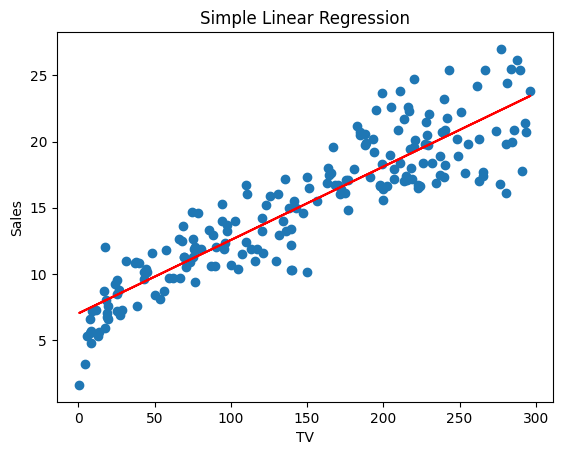


--- Multiple Linear Regression ---
MSE: 2.91
R2: 0.91


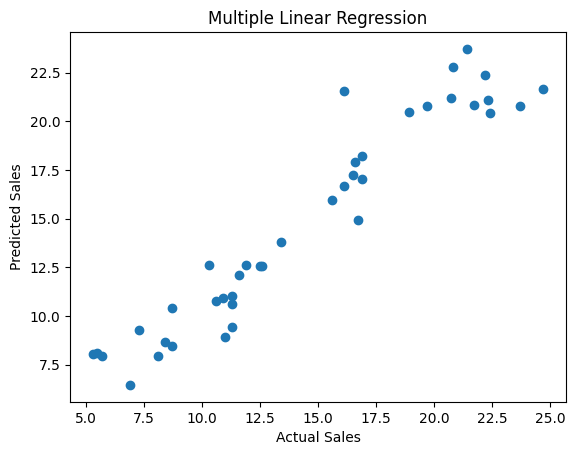


--- Polynomial Regression ---
MSE: 5.68
R2: 0.82


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


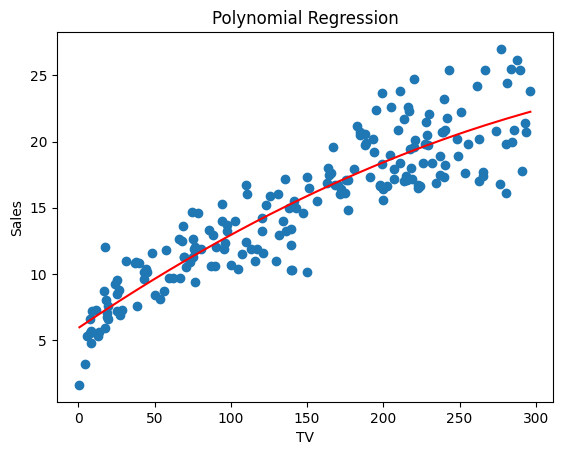

In [ ]:
#REGRESSION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("Advertising.csv")

# Simple Linear Regression
X, y = data[['TV']], data['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\n--- Simple Linear Regression ---")
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2:", round(r2_score(y_test, y_pred), 2))
plt.scatter(X, y)
plt.plot(X, model.predict(X), color='red')
plt.title("Simple Linear Regression")
plt.xlabel("TV")
plt.ylabel("Sales")
plt.show()

# Multiple Linear Regression
X, y = data[['TV', 'Radio', 'Newspaper']], data['Sales']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\n--- Multiple Linear Regression ---")
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2:", round(r2_score(y_test, y_pred), 2))
plt.scatter(y_test, y_pred)
plt.title("Multiple Linear Regression")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.show()

# Polynomial Regression
X, y = data[['TV']], data['Sales']
poly = PolynomialFeatures(2)
X_poly = poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("\n--- Polynomial Regression ---")
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2:", round(r2_score(y_test, y_pred), 2))
X_sorted = np.sort(X, axis=0)
plt.scatter(X, y)
plt.plot(X_sorted, model.predict(poly.transform(X_sorted)), color='red')
plt.title("Polynomial Regression")
plt.xlabel("TV")
plt.ylabel("Sales")
plt.show()

In [ ]:
#KNN
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

# a) Load & preprocess
data = load_iris()
X, y = data.data, data.target
X = StandardScaler().fit_transform(X)

# b) Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

# c) Train KNN (K=5)
model = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

# d) Predict
y_pred = model.predict(X_test)

# e) Evaluate
print("Accuracy :", round(accuracy_score(y_test, y_pred), 2))
print("Precision:", round(precision_score(y_test, y_pred, average='macro'), 2))
print("Recall   :", round(recall_score(y_test, y_pred, average='macro'), 2))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0


In [ ]:
#NBC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# a) Load dataset
data = load_iris()
X, y = data.data, data.target

# b) Preprocess & split
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

# c) Train Naive Bayes
model = GaussianNB().fit(X_train, y_train)

# d) Predict
y_pred = model.predict(X_test)

# e) Evaluate
print("Accuracy:", round(accuracy_score(y_test, y_pred), 2))

Accuracy: 1.0


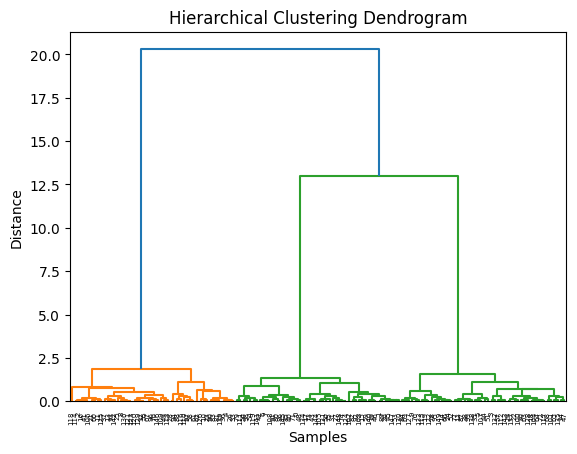

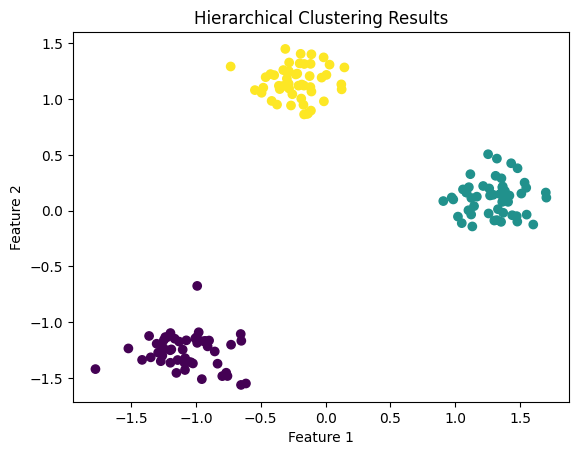

In [ ]:
#HAC
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# a) Generate dataset and perform preprocessing
X, _ = make_blobs(n_samples=150, centers=3, random_state=42)
X_scaled = StandardScaler().fit_transform(X)

# b) Apply hierarchical clustering using Ward linkage
linked = linkage(X_scaled, method='ward')

# c) Generate and display the dendrogram
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

# d) Form clusters based on the dendrogram (3 clusters)
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = model.fit_predict(X_scaled)

# e) Visualize the resulting clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels)
plt.title("Hierarchical Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

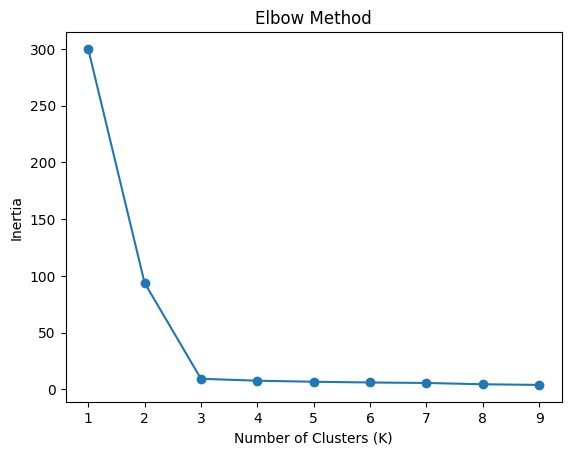

/tmp/ipykernel_716/1186878322.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


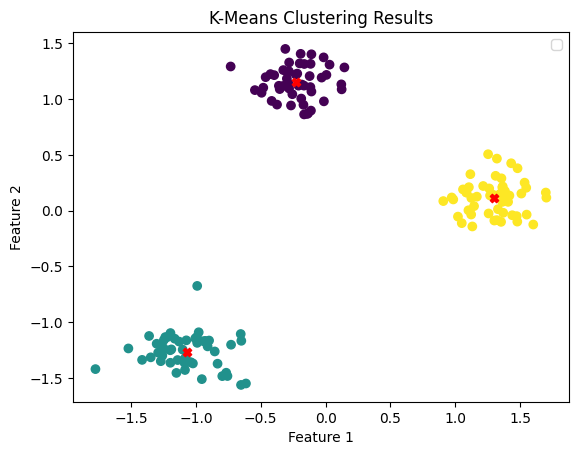

In [ ]:
#KMC
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# a) Generate dataset and perform preprocessing
X, _ = make_blobs(n_samples=150, centers=3, random_state=42)
X_scaled = StandardScaler().fit_transform(X)

# b) Apply K-Means clustering with a suitable number of clusters (K=3)
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X_scaled)

# c) Determine optimal number of clusters using the Elbow Method
inertia = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(1, 10), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

# d) Display cluster assignments and centroids
# e) Visualize the resulting clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], color='red', marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()